# Replication timing of replication-dependent histone genes

Sections 1, 2, 6, 7 and 8 of the original `analysis_slim.ipynb`, here numbered 1-5. Sections 3-5 are the drug-treatment analysis.
The plotting code is unchanged; only the input and output paths are parameters.

Inputs (written by the Nextflow pipeline in `pipeline/`, from public ENCODE files and a public Zenodo archive):

| File | Content |
|---|---|
| `aggregated/per_file_rtscore.parquet` | RT score of each protein-coding gene (gene body) in each of the 108 hg19 wavelet-smoothed tracks |
| `genesets/histones.parquet` | the 66 replication-dependent histone genes and their cluster (HIST1-HIST4) |
| `rnaseq/top5_per_cell.parquet` | the top-5% expressed protein-coding genes of each cell line with RNA-seq (24 labels) |
| `drug/drug_per_gene.csv` | RT score of each histone gene (gene body) in the four drug-treatment tracks: NT, ATRi, Aph06, ATRi+Aph06 (lymphoblastoid JEFF cells, Koundrioukoff et al. 2026) |

Environment variables: `RT_DATA` (input folder, default `results/notebook_inputs`) and `RT_FIGDIR` (output folder, default `figures`).
Each section saves its figure as PDF and PNG and the plotted values as CSV in `RT_FIGDIR`.
RT score: 1 minus the percentile rank of the gene-body signal among all genome bins of the track; 0 = earliest, 1 = latest.

In [1]:
import os
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['pdf.fonttype'] = 42   # editable text in the PDF
np.random.seed(0)                   # fixed strip-plot jitter in section 2

DATA = Path(os.environ.get('RT_DATA', 'results/notebook_inputs')).resolve()
FIGDIR = Path(os.environ.get('RT_FIGDIR', 'figures')).resolve()
FIGDIR.mkdir(parents=True, exist_ok=True)

def show_spines(ax):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color('black')

def save(fig, name):
    fig.savefig(FIGDIR / f'{name}.pdf')
    fig.savefig(FIGDIR / f'{name}.png', dpi=300)

def clamp_rt_axis(ax):
    ax.set_ylim(0, 1)

def finish_rt_axis(ax, title, ylabel=None):
    clamp_rt_axis(ax)
    ax.set_title(title)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    ax.set_xlabel('')
    show_spines(ax)

def assign_histone_class(sym):
    s = str(sym).upper()
    if s.startswith('HIST'):
        rest = s.split('H', 2)
        if len(rest) >= 3:
            head = rest[2]
            if head.startswith('1'):
                return 'H1'
            if head.startswith('2A'):
                return 'H2A'
            if head.startswith('2B'):
                return 'H2B'
            if head.startswith('3'):
                return 'H3'
            if head.startswith('4'):
                return 'H4'
    if s.startswith('H1-'):
        return 'H1'
    if s.startswith('H2AC') or s.startswith('H2A'):
        return 'H2A'
    if s.startswith('H2BC'):
        return 'H2B'
    if s.startswith('H3C') or s.startswith('H3-'):
        return 'H3'
    if s.startswith('H4C') or s.startswith('H4-'):
        return 'H4'
    return 'variant'

## 1. ENCODE histone genes against matched coding genes

/tmp/ipykernel_20656/1029633851.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Protein-coding', 'Top 5% expr', f'RD histone\n(n={len(histone_ids)})'])


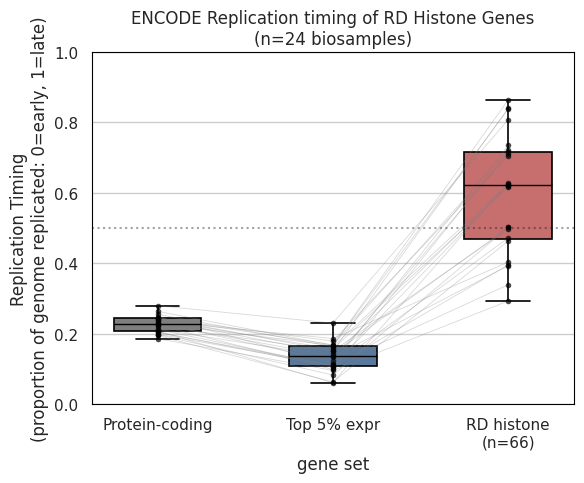

In [2]:
per_file = pd.read_parquet(DATA / 'aggregated/per_file_rtscore.parquet')
histones = pd.read_parquet(DATA / 'genesets/histones.parquet')
top5 = pd.read_parquet(DATA / 'rnaseq/top5_per_cell.parquet')

histone_ids = set(histones['gene_id_unversioned'].astype(str))
top5_pairs = set(zip(top5['cell_line'].astype(str), top5['gene_id_unversioned'].astype(str)))

base = per_file[['cell_line', 'group', 'gene_id', 'rt_score']].dropna().copy()
base['gene_id'] = base['gene_id'].astype(str)
base['gene_id_unversioned'] = base['gene_id'].str.split('.').str[0]
base = base[(base['rt_score'] >= 0) & (base['rt_score'] <= 1)]

all_coding = (
    base.groupby(['cell_line', 'group'], as_index=False)
    .agg(rt_med=('rt_score', 'median'))
)
all_coding['set'] = 'all_coding'

top5_expr = base[
    [pair in top5_pairs for pair in zip(base['cell_line'].astype(str), base['gene_id_unversioned'])]
].groupby(['cell_line', 'group'], as_index=False).agg(rt_med=('rt_score', 'median'))
top5_expr['set'] = 'top5_expr'

histone = (
    base[base['gene_id_unversioned'].isin(histone_ids)]
    .groupby(['cell_line', 'group'], as_index=False)
    .agg(rt_med=('rt_score', 'median'))
)
histone['set'] = 'rd_histone'

plot_long = pd.concat([all_coding, top5_expr, histone], ignore_index=True)
pivot = plot_long.pivot_table(
    index=['cell_line', 'group'], columns='set', values='rt_med'
).reset_index()

order = ['all_coding', 'top5_expr', 'rd_histone']
palette = {'all_coding': '#7f7f7f', 'top5_expr': '#4c78a8', 'rd_histone': '#d65f5f'}
plot_long = pivot[~pivot['top5_expr'].isna()].melt(
    id_vars=['cell_line', 'group'], value_vars=order,
    var_name='set', value_name='rt_med'
)

fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(
    data=plot_long, x='set', y='rt_med', order=order,
    hue='set', palette=palette, ax=ax,
    width=0.5, showfliers=False, legend=False,
    linewidth=1.2, linecolor='black',
    medianprops=dict(color='black', linewidth=1),
)
sns.stripplot(
    data=plot_long, x='set', y='rt_med', order=order,
    ax=ax, color='black', size=4, alpha=0.7, jitter=False
)
for cl in pivot['cell_line']:
    row = pivot[pivot.cell_line == cl].iloc[0]
    ys = [row[s] if not pd.isna(row[s]) else np.nan for s in order]
    ax.plot(range(len(order)), ys, color='gray', alpha=0.3, lw=0.6)

ax.set_ylabel('Replication Timing\n(proportion of genome replicated: 0=early, 1=late)')
ax.set_ylim(0, 1)
ax.set_title(f'ENCODE Replication timing of RD Histone Genes\n(n=24 biosamples)')
ax.axhline(0.5, color='k', linestyle=':', alpha=0.4)
ax.set_xticklabels(['Protein-coding', 'Top 5% expr', f'RD histone\n(n={len(histone_ids)})'])
ax.set_xlabel('gene set')
show_spines(ax)
plt.tight_layout()
save(fig, 'section1_histone_vs_coding')
pivot.to_csv(FIGDIR / 'section1_histone_vs_coding_values.csv', index=False)
plt.show()


## 2. ENCODE histone clusters

/tmp/ipykernel_20656/3355828187.py:50: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=plot_df, x='cluster', y='rt_med', order=order, dodge=True,


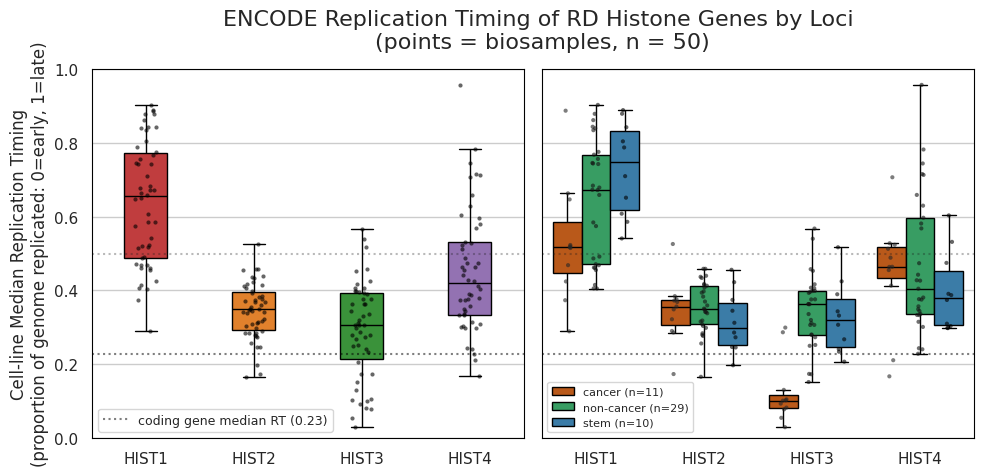

In [3]:
per_file = pd.read_parquet(DATA / 'aggregated/per_file_rtscore.parquet')
histones = pd.read_parquet(DATA / 'genesets/histones.parquet')
hist = histones[['gene_id_unversioned', 'histone_cluster']].dropna().copy()
hist['gene_id_unversioned'] = hist['gene_id_unversioned'].astype(str)

base = per_file[['cell_line', 'group', 'gene_id', 'rt_score']].dropna().copy()
base['gene_id'] = base['gene_id'].astype(str)
base['gene_id_unversioned'] = base['gene_id'].str.split('.').str[0]
base = base[(base['rt_score'] >= 0) & (base['rt_score'] <= 1)]

cluster_df = (
    base.merge(hist, on='gene_id_unversioned', how='inner')
    .groupby(['cell_line', 'group', 'histone_cluster'], as_index=False)
    .agg(rt_med=('rt_score', 'median'), n_genes=('gene_id', 'nunique'))
    .rename(columns={'histone_cluster': 'cluster'})
)
all_medians = base.groupby('cell_line')['rt_score'].median().rename('all_coding_med')
cluster_df = cluster_df.merge(all_medians, on='cell_line', how='left')

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
clust_palette = {'HIST1':'#d62728','HIST2':'#ff7f0e','HIST3':'#2ca02c','HIST4':'#9467bd'}
group_palette = {'cancer':'#d35400','non-cancer':'#27ae60','stem':'#2980b9'}
plot_df = cluster_df.dropna(subset=['rt_med'])
plot_df = plot_df[plot_df.n_genes > 0]
order = ['HIST1', 'HIST2', 'HIST3', 'HIST4']

sns.boxplot(
    data=plot_df, x='cluster', y='rt_med', order=order, showfliers=False,
    width=0.4, linecolor='black',
    hue='cluster', palette=clust_palette, ax=axes[0], legend=False,
)
sns.stripplot(
    data=plot_df, x='cluster', y='rt_med', order=order,
    ax=axes[0], color='black', size=3, jitter=True, alpha=0.6
)
all_baseline = cluster_df.all_coding_med.median()
axes[0].axhline(all_baseline, color='black', linestyle=':', alpha=0.5,
                label=f'coding gene median RT ({all_baseline:.2f})')
axes[0].set_ylabel('Cell-line Median Replication Timing\n(proportion of genome replicated: 0=early, 1=late)')
axes[0].set_ylim(0, 1)
axes[0].set_xlabel('')
axes[0].legend(loc='lower left', fontsize=9)

sns.boxplot(
    data=plot_df, x='cluster', y='rt_med', hue='group', order=order,
    hue_order=['cancer', 'non-cancer', 'stem'],
    palette=group_palette, ax=axes[1], width=0.8,
    showfliers=False, linecolor='black',
)
sns.stripplot(data=plot_df, x='cluster', y='rt_med', order=order, dodge=True,
              hue='group', hue_order=['cancer','non-cancer','stem'], legend=False,
              color='black', size=3, alpha=0.6, ax=axes[1])
axes[1].axhline(all_baseline, color='black', linestyle=':', alpha=0.5)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel('')
axes[1].set_xlabel('')
axes[1].legend(loc='lower left', fontsize=8)

n_per_group = plot_df[plot_df['cluster'] == 'HIST1']['group'].value_counts()
handles, labels = axes[1].get_legend_handles_labels()
new_labels = [f"{l} (n={n_per_group.get(l, 0)})" for l in labels]
axes[1].legend(handles, new_labels, loc='lower left', fontsize=8)

for ax in axes:
    ax.axhline(0.5, color='k', linestyle=':', alpha=0.3)
    show_spines(ax)
fig.suptitle('ENCODE Replication Timing of RD Histone Genes by Loci \n(points = biosamples, n = 50)',
             fontsize=16, x=0.55, y=.95)
plt.tight_layout()
save(fig, 'section2_histone_clusters')
cluster_df.to_csv(FIGDIR / 'section2_histone_clusters_values.csv', index=False)
plt.show()


## Drug-treatment Repli-seq (sections 3-5)

Data: Koundrioukoff et al. 2026 (Nucleic Acids Research, doi:10.1093/nar/gkag315), lymphoblastoid JEFF cells.
The six-fraction Repli-seq bigWigs come from the authors' Zenodo archive (doi:10.5281/zenodo.19093559, CC BY 4.0).
Only four conditions have all six fractions in that archive: NT (untreated, replicate 3), ATRi, Aph06 (aphidicolin) and ATRi+Aph06 (replicate 1 each).
The pipeline builds one track per condition with the same weighted average and J7 wavelet smoothing as the ENCODE UW tracks.
Each gene's RT score uses its gene body, as in sections 1-2, ranked among all 10 kb genome bins.
There is one track per condition, so these sections show no replicate statistics.

## 3. Drug treatment: H1 versus core histones

/tmp/ipykernel_20656/4253209332.py:19: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=drug, x='condition', y='rt_score', hue='class_group',
/tmp/ipykernel_20656/4253209332.py:32: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=drug, x='condition', y='rt_score', hue='histone_class',


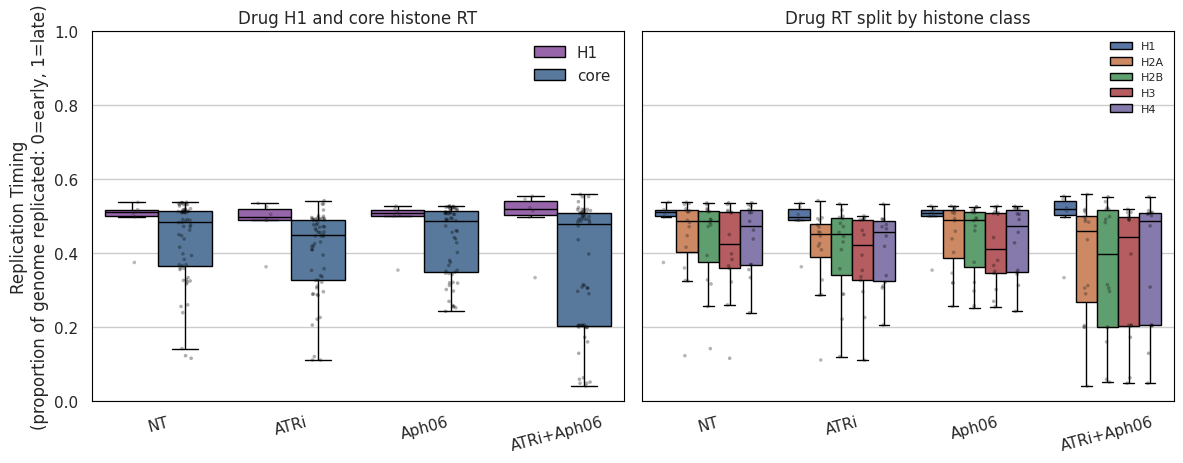

drug H1-vs-core contrasts:
 condition       H1     core  h1_minus_core
        NT 0.509860 0.482432       0.027428
      ATRi 0.496471 0.447460       0.049011
     Aph06 0.506909 0.487110       0.019799
ATRi+Aph06 0.518031 0.477694       0.040337


In [4]:
drug = pd.read_csv(DATA / 'drug/drug_per_gene.csv')
drug = drug[drug['histone_class'].isin(['H1', 'H2A', 'H2B', 'H3', 'H4'])].copy()
drug['class_group'] = np.where(drug['histone_class'] == 'H1', 'H1', 'core')
order = ['NT', 'ATRi', 'Aph06', 'ATRi+Aph06']

summary = (
    drug.groupby(['condition', 'class_group'], as_index=False)
    .agg(rt_med=('rt_score', 'median'), n=('gene_id', 'nunique'))
)
drug_h1_core = summary.pivot(index='condition', columns='class_group', values='rt_med').reset_index()
drug_h1_core['h1_minus_core'] = drug_h1_core['H1'] - drug_h1_core['core']
drug_h1_core = drug_h1_core.set_index('condition').loc[order].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
sns.boxplot(data=drug, x='condition', y='rt_score', hue='class_group', linecolor='black',
            order=order, hue_order=['H1', 'core'],
            palette={'H1': '#9b59b6', 'core': '#4c78a8'},
            ax=axes[0], showfliers=False)
sns.stripplot(data=drug, x='condition', y='rt_score', hue='class_group',
              order=order, hue_order=['H1', 'core'],
              dodge=True, color='black', size=2.6, alpha=0.32,
              ax=axes[0], legend=False)
finish_rt_axis(axes[0], 'Drug H1 and core histone RT', 'rt_score')
axes[0].tick_params(axis='x', rotation=15)
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles[:2], labels[:2], title='', frameon=False)
axes[0].set_ylabel('Replication Timing\n(proportion of genome replicated: 0=early, 1=late)')

class_order = ['H1', 'H2A', 'H2B', 'H3', 'H4']
sns.boxplot(data=drug, x='condition', y='rt_score', hue='histone_class', linecolor='black',
            order=order, hue_order=class_order, ax=axes[1], showfliers=False)
sns.stripplot(data=drug, x='condition', y='rt_score', hue='histone_class',
              order=order, hue_order=class_order,
              dodge=True, color='black', size=2.6, alpha=0.32,
              ax=axes[1], legend=False)
finish_rt_axis(axes[1], 'Drug RT split by histone class', None)
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(title='', frameon=False, fontsize=8, ncol=1)

plt.tight_layout()
save(fig, 'section3_drug_h1_core')
drug_h1_core.to_csv(FIGDIR / 'section3_drug_h1_core_values.csv', index=False)
plt.show()

print('drug H1-vs-core contrasts:')
print(drug_h1_core.to_string(index=False))

## 4. Drug response by histone gene

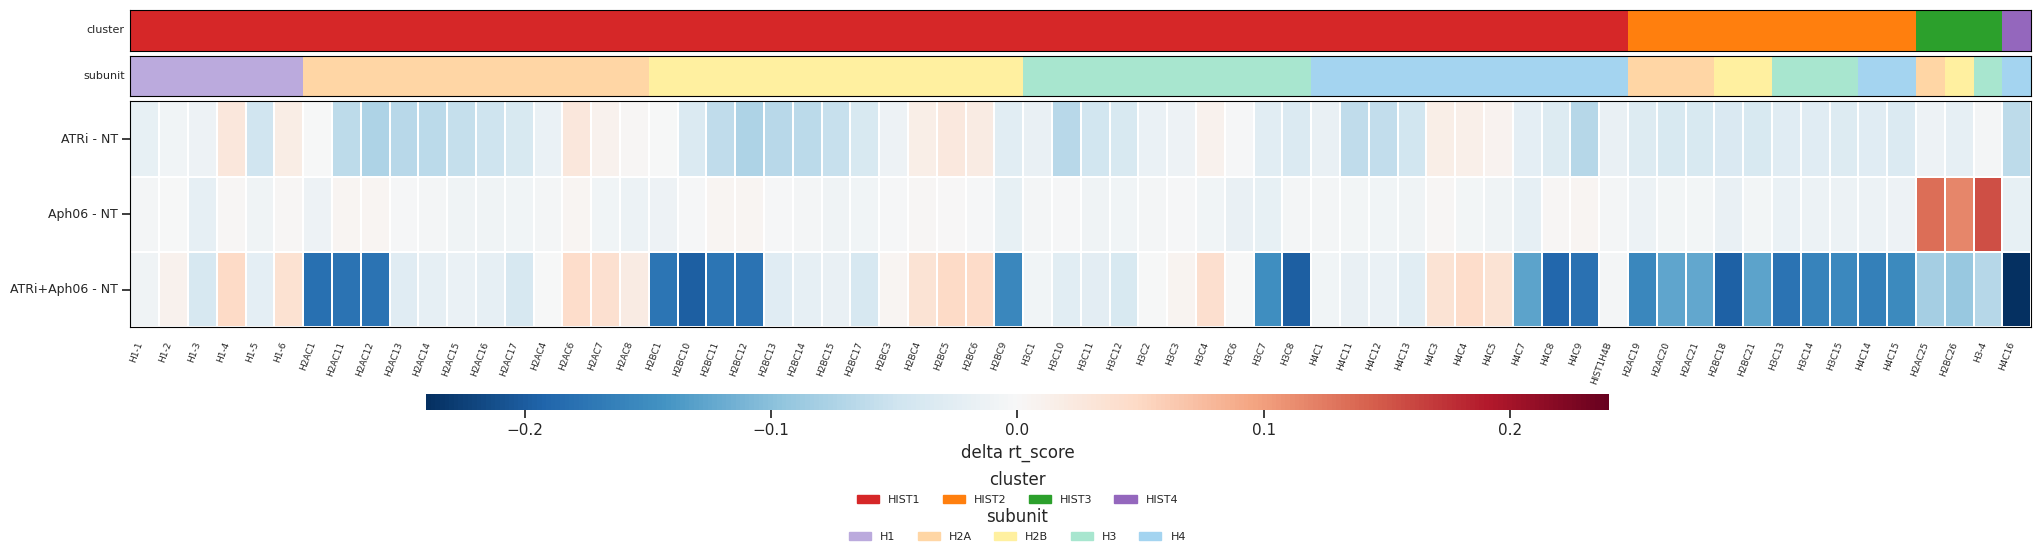

Direction consistency across treatments:
consistent_direction
earlier in all    42
mixed             18
later in all       6

Largest consistent earlier shifts:
gene_name histone_cluster histone_class  mean_delta  max_abs_delta  delta_ATRi  delta_Aph06  delta_ATRi+Aph06
    H4C16           HIST4            H4   -0.107883       0.240004   -0.063123    -0.020523         -0.240004
   H2BC18           HIST2           H2B   -0.083095       0.195179   -0.035825    -0.018279         -0.195179
     H3C8           HIST1            H3   -0.079004       0.197593   -0.034122    -0.005297         -0.197593
   H2BC10           HIST1           H2B   -0.078290       0.197054   -0.034351    -0.003466         -0.197054
    H3C13           HIST2            H3   -0.074540       0.177797   -0.029608    -0.016216         -0.177797
    H4C14           HIST2            H4   -0.069508       0.164280   -0.029348    -0.014895         -0.164280
    H3C14           HIST2            H3   -0.068414       0.160937   

In [5]:
drug = pd.read_csv(DATA / 'drug/drug_per_gene.csv')
histones = pd.read_parquet(DATA / 'genesets/histones.parquet').copy()
histones['histone_class'] = histones['gene_name'].apply(assign_histone_class)
class_order = ['H1', 'H2A', 'H2B', 'H3', 'H4']
class_rank = {c: i for i, c in enumerate(class_order)}
cluster_rank = {'HIST1': 0, 'HIST2': 1, 'HIST3': 2, 'HIST4': 3}
histones['class_rank'] = histones['histone_class'].map(class_rank).fillna(99).astype(int)
histones['cluster_rank'] = histones['histone_cluster'].map(cluster_rank).fillna(99).astype(int)
histone_order = histones.sort_values(['cluster_rank', 'class_rank', 'chrom', 'tss'])[
    ['gene_id', 'gene_name', 'histone_cluster', 'histone_class', 'cluster_rank', 'class_rank']
].copy()

condition_order = ['NT', 'ATRi', 'Aph06', 'ATRi+Aph06']
treatment_order = ['ATRi', 'Aph06', 'ATRi+Aph06']

wide = (
    drug.pivot_table(
        index=['gene_id', 'gene_name', 'histone_cluster', 'histone_class'],
        columns='condition', values='rt_score', aggfunc='mean'
    )
    .reset_index()
)
wide = wide.dropna(subset=['NT'])
for cond in treatment_order:
    wide[f'delta_{cond}'] = wide[cond] - wide['NT']

delta_cols = [f'delta_{cond}' for cond in treatment_order]
resp = wide.dropna(subset=delta_cols).copy()
resp['mean_delta'] = resp[delta_cols].mean(axis=1)
resp['max_abs_delta'] = resp[delta_cols].abs().max(axis=1)
resp['n_earlier'] = (resp[delta_cols] < 0).sum(axis=1)
resp['n_later'] = (resp[delta_cols] > 0).sum(axis=1)
resp['consistent_direction'] = np.where(
    resp['n_earlier'].eq(len(treatment_order)), 'earlier in all',
    np.where(resp['n_later'].eq(len(treatment_order)), 'later in all', 'mixed')
)
resp = histone_order[['gene_id', 'cluster_rank', 'class_rank']].merge(resp, on='gene_id', how='inner')
resp = resp.sort_values(['cluster_rank', 'class_rank', 'gene_name']).reset_index(drop=True)

cluster_colors = {'HIST1': '#d62728', 'HIST2': '#ff7f0e', 'HIST3': '#2ca02c', 'HIST4': '#9467bd'}
class_colors = {'H1': '#bbaadd', 'H2A': '#ffd6a5', 'H2B': '#fff0a0', 'H3': '#a8e6cf', 'H4': '#a4d4f0'}
cluster_levels = ['HIST1', 'HIST2', 'HIST3', 'HIST4']
cluster_code = pd.Categorical(resp['histone_cluster'], categories=cluster_levels, ordered=True).codes
class_code = pd.Categorical(resp['histone_class'], categories=class_order, ordered=True).codes
heat = resp[delta_cols].copy()
heat.index = resp['gene_name']
v = max(float(np.nanmax(np.abs(heat.to_numpy()))), 0.05)

fig, axes = plt.subplots(
    3, 1, figsize=(max(14, 0.32 * len(resp)), 6.1),
    gridspec_kw={'height_ratios': [0.18, 0.18, 1.0], 'hspace': 0.05},
    sharex=True
)
cbar_ax = fig.add_axes([0.22, 0.205, 0.56, 0.026])
sns.heatmap(
    pd.DataFrame([cluster_code], index=['cluster'], columns=resp['gene_name']),
    ax=axes[0],
    cmap=mcolors.ListedColormap([cluster_colors[k] for k in cluster_levels]),
    cbar=False,
    xticklabels=False,
    yticklabels=True,
    linewidths=0,
)
sns.heatmap(
    pd.DataFrame([class_code], index=['subunit'], columns=resp['gene_name']),
    ax=axes[1],
    cmap=mcolors.ListedColormap([class_colors[k] for k in class_order]),
    cbar=False,
    xticklabels=False,
    yticklabels=True,
    linewidths=0,
)
hm = sns.heatmap(
    heat.T,
    ax=axes[2],
    cmap='RdBu_r',
    vmin=-v,
    vmax=v,
    center=0,
    yticklabels=[f'{c} - NT' for c in treatment_order],
    xticklabels=resp['gene_name'].tolist(),
    linewidths=0.15,
    linecolor='white',
    cbar_ax=cbar_ax,
    cbar_kws={'label': 'delta rt_score', 'orientation': 'horizontal'},
)
cbar_ax.xaxis.set_label_position('bottom')
cbar_ax.xaxis.set_ticks_position('bottom')
for ax in axes[:2]:
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
    ax.tick_params(axis='x', length=0)
    ax.tick_params(axis='y', length=0, pad=4)
    show_spines(ax)
axes[2].set_xlabel('')
axes[2].set_ylabel('')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=70, ha='right', fontsize=6.5)
axes[2].set_yticklabels(axes[2].get_yticklabels(), rotation=0, fontsize=9)
axes[2].tick_params(axis='y', left=True, labelleft=True, pad=3)
show_spines(axes[2])

cluster_handles = [mpatches.Patch(color=cluster_colors[k], label=k) for k in cluster_levels]
class_handles = [mpatches.Patch(color=class_colors[k], label=k) for k in class_order]
fig.legend(handles=cluster_handles, title='cluster', loc='upper center',
           bbox_to_anchor=(0.5, 0.12), ncol=4, frameon=False, fontsize=8, title_fontsize=12)
fig.legend(handles=class_handles, title='subunit', loc='upper center',
           bbox_to_anchor=(0.5, 0.06), ncol=5, frameon=False, fontsize=8, title_fontsize=12)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.34, top=0.86, hspace=0.05)
for ax in axes:
    ax.set_xlim(0, len(resp))
save(fig, 'section4_drug_gene_response')
plt.show()

responder_threshold = 0.05
resp['drug_responder'] = resp['mean_delta'].le(-responder_threshold) & resp['n_earlier'].ge(2)
print('Direction consistency across treatments:')
print(resp['consistent_direction'].value_counts().to_string())
print()
print('Largest consistent earlier shifts:')
cols = ['gene_name', 'histone_cluster', 'histone_class', 'mean_delta', 'max_abs_delta'] + delta_cols
print(resp[resp['consistent_direction'] == 'earlier in all']
      .sort_values('mean_delta').head(12)[cols].to_string(index=False))
print()
print('Treatment-response delta correlations:')
print(resp[delta_cols].corr(method='spearman').round(2).to_string())
resp.to_csv(FIGDIR / 'section4_drug_gene_response_values.csv', index=False)

## 5. Drug response by histone repeat element

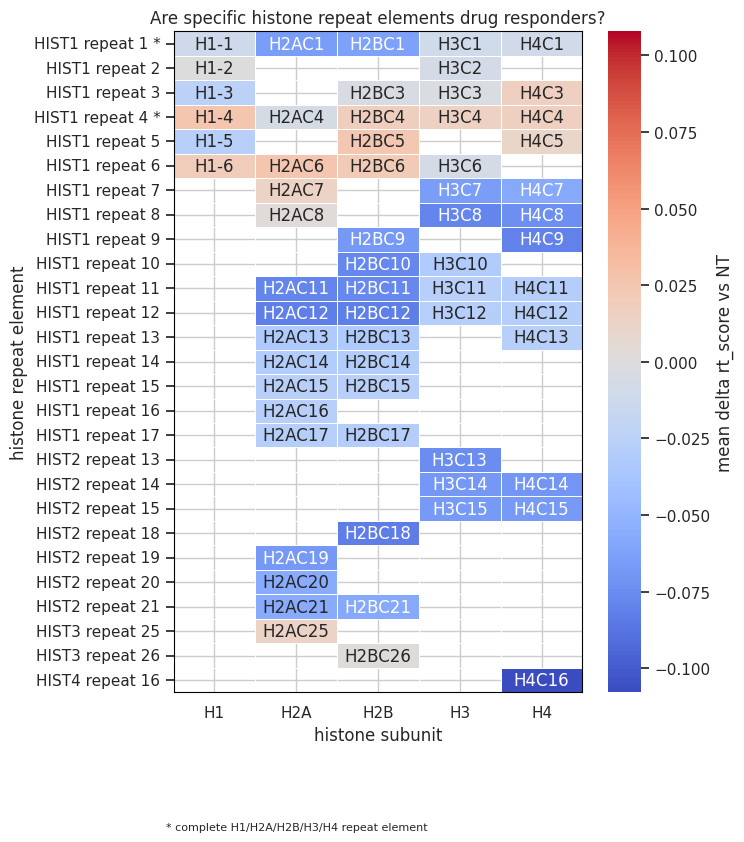

Most drug-responsive repeat elements by mean delta:
                 n_subunits  mean_delta  n_earlier  complete
repeat_element                                              
HIST4 repeat 16           1   -0.107883          1     False
HIST2 repeat 18           1   -0.083095          1     False
HIST2 repeat 13           1   -0.074540          1     False
HIST1 repeat 9            2   -0.074085          2     False
HIST2 repeat 14           2   -0.068961          2     False
HIST2 repeat 19           1   -0.067519          1     False
HIST2 repeat 15           2   -0.066887          2     False
HIST2 repeat 21           2   -0.057266          2     False
HIST2 repeat 20           1   -0.057262          1     False
HIST1 repeat 12           4   -0.055277          4     False
HIST1 repeat 10           2   -0.055066          2     False
HIST1 repeat 11           4   -0.053041          4     False


In [6]:
drug = pd.read_csv(DATA / 'drug/drug_per_gene.csv')
histones = pd.read_parquet(DATA / 'genesets/histones.parquet').copy()
histones['histone_class'] = histones['gene_name'].apply(assign_histone_class)
class_order = ['H1', 'H2A', 'H2B', 'H3', 'H4']
class_rank = {c: i for i, c in enumerate(class_order)}
cluster_rank = {'HIST1': 0, 'HIST2': 1, 'HIST3': 2, 'HIST4': 3}
histones['class_rank'] = histones['histone_class'].map(class_rank).fillna(99).astype(int)
histones['cluster_rank'] = histones['histone_cluster'].map(cluster_rank).fillna(99).astype(int)

condition_order = ['NT', 'ATRi', 'Aph06', 'ATRi+Aph06']
treatment_order = ['ATRi', 'Aph06', 'ATRi+Aph06']
wide = (
    drug.pivot_table(
        index=['gene_id', 'gene_name', 'histone_cluster', 'histone_class'],
        columns='condition', values='rt_score', aggfunc='mean'
    )
    .reset_index()
    .dropna(subset=['NT'])
)
for cond in treatment_order:
    wide[f'delta_{cond}'] = wide[cond] - wide['NT']
delta_cols = [f'delta_{cond}' for cond in treatment_order]
resp = wide.dropna(subset=delta_cols).copy()
resp['mean_delta'] = resp[delta_cols].mean(axis=1)
resp['n_earlier'] = (resp[delta_cols] < 0).sum(axis=1)
resp = histones[['gene_id', 'cluster_rank', 'class_rank']].merge(resp, on='gene_id', how='inner')

def histone_repeat_number(symbol):
    s = str(symbol).upper()
    patterns = [
        r'^H1-(\d+)$',
        r'^H2AC(\d+)$',
        r'^H2BC(\d+)$',
        r'^H3C(\d+)$',
        r'^H4C(\d+)$',
    ]
    for pat in patterns:
        m = re.match(pat, s)
        if m:
            return int(m.group(1))
    return np.nan

resp['repeat_number'] = resp['gene_name'].map(histone_repeat_number)
repeat_genes = resp.dropna(subset=['repeat_number']).copy()
repeat_genes['repeat_number'] = repeat_genes['repeat_number'].astype(int)
repeat_genes['repeat_element'] = repeat_genes['histone_cluster'] + ' repeat ' + repeat_genes['repeat_number'].astype(str)
repeat_genes = repeat_genes.sort_values(['cluster_rank', 'repeat_number', 'class_rank'])
repeat_order = (
    repeat_genes[['histone_cluster', 'repeat_number', 'repeat_element', 'cluster_rank']]
    .drop_duplicates()
    .sort_values(['cluster_rank', 'repeat_number'])['repeat_element']
    .tolist()
)
repeat_mat = (
    repeat_genes.pivot_table(index='repeat_element', columns='histone_class',
                             values='mean_delta', aggfunc='mean')
    .reindex(index=repeat_order, columns=class_order)
)
repeat_annot = (
    repeat_genes.pivot_table(index='repeat_element', columns='histone_class',
                             values='gene_name', aggfunc='first')
    .reindex(index=repeat_order, columns=class_order)
)
repeat_v = max(float(np.nanmax(np.abs(repeat_mat.to_numpy()))), 0.05)
repeat_complete = repeat_mat.notna().sum(axis=1).eq(len(class_order))
repeat_labels = [f'{idx} *' if repeat_complete.loc[idx] else idx for idx in repeat_mat.index]

fig, ax = plt.subplots(figsize=(7.2, max(5.5, 0.34 * len(repeat_mat))))
sns.heatmap(
    repeat_mat,
    ax=ax,
    cmap='coolwarm',
    vmin=-repeat_v,
    vmax=repeat_v,
    center=0,
    annot=repeat_annot,
    fmt='',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'mean delta rt_score vs NT'},
)
ax.set_xlabel('histone subunit')
ax.set_ylabel('histone repeat element')
ax.set_title('Are specific histone repeat elements drug responders?')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticks(np.arange(len(repeat_mat.index)) + 0.5)
ax.set_yticklabels(repeat_labels, rotation=0)
ax.tick_params(axis='y', left=True, labelleft=True)
show_spines(ax)
fig.text(0.24, 0.03, '* complete H1/H2A/H2B/H3/H4 repeat element', fontsize=8)
fig.subplots_adjust(left=0.25, right=0.96, bottom=0.18, top=0.90)
save(fig, 'section5_drug_repeat_elements')
plt.show()

responder_threshold = 0.05
repeat_summary = repeat_genes.groupby('repeat_element').agg(
    n_subunits=('histone_class', 'nunique'),
    mean_delta=('mean_delta', 'mean'),
    n_earlier=('n_earlier', lambda x: int((x >= 2).sum())),
).reindex(repeat_order)
repeat_summary['complete'] = repeat_complete.reindex(repeat_order).values
print('Most drug-responsive repeat elements by mean delta:')
print(repeat_summary.sort_values('mean_delta').head(12).to_string())
repeat_summary.to_csv(FIGDIR / 'section5_drug_repeat_elements_values.csv')